# Context selector on the AACR 50% set: non-LLM models (laptop)

Which hunks should be reviewed with more context than `H01_min`? This notebook trains selectors
that answer from facts known **before** any review, on the 93-PR, 928-hunk, four-level run of
`docs/aacr_50pct_run.md`, and scores them by what the reviewer would then have found.

- **Label** (`LABEL = "wider"`): some wider level (`H02_function`, `H03_file`, `H04_callees1`)
  covers more reference comments than `H01_min`; 190 of 928 hunks.
- **Selector**: rank hunks by the model's score and upgrade them from `H01_min` to one wider
  level, in that order, until a share of the extra tokens is spent. Every upgrade level is scored;
  `MAIN_UP` is the one used for the paired comparisons.
- **Models**: logistic regression, random forest and boosted trees on tabular features (sizes,
  trace counts, every built level's token counts), on the `H01_min` text (TF-IDF), and on both;
  a language-only control; shuffled labels for the chance level.
- **Folds**: 5 folds of whole repositories, set by a fixed rule in plain Python, so the
  LLM notebook (`selector50_llm_a100.ipynb`) gets exactly the same folds on any machine.
- **Baselines**: always each level, random upgrade order (1,000 orders), cheapest first,
  and the hindsight ranking (an upper bound, not a method).

Inputs: the folder `data/aacr_hunk_50%_selector_files` (`hunk_outcomes.json`, `coverage.csv`,
`context_levels_slim.jsonl`). Runs on a laptop in a few minutes. Kernel: **CS536 (conda cs536)**.

## 1. Setup

In [1]:
import os, sys, json, hashlib, zipfile, time, math, warnings, collections, gc
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB and not any(k in sys.prefix for k in ("/envs/cs536", "/.venv")):
    raise RuntimeError(
        f"Wrong kernel: {sys.executable}\n"
        "In VS Code: kernel picker (top right) -> Select Another Kernel -> Python Environments -> "
        "cs536 (~/anaconda3/envs/cs536/bin/python), then Restart and Run All.")
print("Python:", sys.executable)
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

def repo_root():
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "AGENTS.md").exists():
            return d
    return Path.cwd()
REPO = None if IN_COLAB else repo_root()

# Folder (or zip) with hunk_outcomes.json, coverage.csv and context_levels_slim.jsonl.
LOCAL_DATA_PATH = str(REPO / "data" / "aacr_hunk_50%_selector_files") if REPO else ""
COLAB_DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/LH/ML2/aacr_hunk_50%_selector_files"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
DATA_PATH = os.environ.get("SELECTOR_DATA", COLAB_DATA_PATH if IN_COLAB else LOCAL_DATA_PATH)
OUT_DIR = Path(os.environ.get("SELECTOR_OUT", "/content/drive/MyDrive/Colab Notebooks/LH/ML2/selector50_nonllm_results"
                              if IN_COLAB else str(REPO / "results" / "selector50_nonllm")))

def find_inputs(path):
    """The three input files, found by name under a folder (a zip is unzipped first)."""
    p = Path(path)
    if p.is_file() and p.suffix == ".zip":
        dest = Path("/content/selector50_data" if IN_COLAB else p.with_suffix(""))
        if not dest.exists():
            print(f"Unzipping {p} -> {dest}")
            with zipfile.ZipFile(p) as z:
                z.extractall(dest)
        p = dest
    if not p.is_dir():
        raise FileNotFoundError(f"DATA_PATH does not exist: {p}")
    def first(*names):
        for name in names:
            hits = sorted(h for h in p.rglob(name) if "__MACOSX" not in h.parts and not h.name.startswith("._"))
            if hits:
                return hits[0]
        return None
    files = {"outcomes": first("hunk_outcomes.json"),
             "contexts": first("context_levels_slim.jsonl", "context_levels.jsonl"),
             "coverage": first("coverage.csv")}
    missing = [k for k, v in files.items() if v is None]
    if missing:
        raise FileNotFoundError(f"Missing {missing} under {p}: need hunk_outcomes.json, "
                                "context_levels_slim.jsonl and coverage.csv")
    return files

FILES = find_inputs(DATA_PATH)
for k, v in FILES.items():
    print(f"{k:9s} {v}")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Results go to", OUT_DIR)

Python: /Users/penglihua/anaconda3/envs/cs536/bin/python
outcomes  /Users/penglihua/Desktop/GitHub/CS536_Project/data/aacr_hunk_50%_selector_files/hunk_outcomes.json
contexts  /Users/penglihua/Desktop/GitHub/CS536_Project/data/aacr_hunk_50%_selector_files/context_levels_slim.jsonl
coverage  /Users/penglihua/Desktop/GitHub/CS536_Project/data/aacr_hunk_50%_selector_files/coverage.csv
Results go to /Users/penglihua/Desktop/GitHub/CS536_Project/results/selector50_nonllm


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.1.1 | scikit-learn 1.9.1


## 2. Configuration

Change settings here, not further down.

In [3]:
LEVELS = ["H01_min", "H02_function", "H03_file", "H04_callees1"]   # the four reviewed levels
BASE_LEVEL = "H01_min"                                           # every hunk's default
UPGRADE_LEVELS = ["H02_function", "H03_file", "H04_callees1"]    # a selected hunk goes to one of these
MAIN_UP = "H02_function"     # the upgrade level of the main comparison (cheapest way to the gain, aacr_50pct_run.md)

LABEL = "wider"              # "wider": some wider level covers more references than H01_min (190 hunks);
                             # "wider_weighted": the same with severity weights
WEIGHTINGS = {"flat": (1, 1, 1), "linear": (3, 2, 1), "agreed": (5, 2, 0.5), "steep": (25, 5, 1),
              "blocking_only": (1, 0, 0)}
TARGET_WEIGHTING = "agreed"  # the severity score used for every budget result

# Folds: CV = "group5" (5 folds of whole repositories, same rule in both notebooks) or "repo"
# (leave one repository out, 37 folds). Keep "group5" to compare with the LLM notebook.
CV = "group5"
N_FOLDS = 5
FOLD_SEED = 0

# Budgets: every hunk starts at BASE_LEVEL; a selector spends a share of the extra tokens that
# upgrading every hunk would cost. 1.0 is always the upgrade level.
SPEND = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]
TARGET_SPEND = 0.3           # 20% of hunks are positive; 30% of the extra tokens is the main point
N_RANDOM = 1000
N_BOOT = 2000
REFERENCE_METHOD = "tabular, logistic"     # the pre-declared baseline every method is compared with

SEEDS = [0, 1, 2]            # random forest and boosted trees; scores are averaged over seeds
N_SHUFFLE = 20               # shuffled-label repeats for the chance level
TEXT_SVD = 64                # text dimensions given to the tree models (TF-IDF -> SVD inside each fold)
PLOT_METHODS = ["tabular, logistic", "tabular, random forest", "tabular, boosted trees",
                "text, logistic", "tabular+text, logistic", "tabular+text, random forest",
                "tabular+text, boosted trees", "language only, logistic"]
FIG_NAME = "frontier_nonllm.png"

## 3. Load the outcome table and check it against `coverage.csv`

In [4]:
with open(FILES["outcomes"]) as f:
    OUT = json.load(f)
assert OUT["levels"] == LEVELS, OUT["levels"]
rows = OUT["rows"]
hunks = pd.DataFrame([{k: v for k, v in r.items() if k != "levels"} for r in rows])
hunks["repo"] = hunks["pr"].str.rsplit("__", n=1).str[0]
H = len(hunks)
hunk_pos = {h: i for i, h in enumerate(hunks["hunk"])}

ref_rows = [{"pr": pr, "ref": int(k), **r} for pr, refs in OUT["refs"].items() for k, r in refs.items()]
refs_df = pd.DataFrame(ref_rows).sort_values(["pr", "ref"]).reset_index(drop=True)
refs_df["repo"] = refs_df["pr"].str.rsplit("__", n=1).str[0]
R = len(refs_df)
ref_pos = {(p, k): i for i, (p, k) in enumerate(zip(refs_df["pr"], refs_df["ref"]))}

L = len(LEVELS)
COV = np.zeros((H, L, R), dtype=bool)     # COV[h, l, r]: hunk h's review at level l covers reference r
TOK = np.zeros((H, L))                    # reviewer input tokens of hunk h at level l
for r in rows:
    i = hunk_pos[r["hunk"]]
    for j, lv in enumerate(LEVELS):
        c = r["levels"][lv]
        TOK[i, j] = c["tokens"]
        for k in c["covered"]:
            COV[i, j, ref_pos[(r["pr"], k)]] = True

# Check: every (PR, level) union equals coverage.csv.
cc = pd.read_csv(FILES["coverage"])
cc = cc[cc["covered"].astype(str) == "True"]
want = collections.defaultdict(set)
for e, lv, k in zip(cc["entry"], cc["level"], cc["reference"]):
    want[(e, lv)].add(int(k))
got = collections.defaultdict(set)
for r in rows:
    for lv in LEVELS:
        got[(r["pr"], lv)].update(r["levels"][lv]["covered"])
bad = [k for k in set(want) | set(got) if want[k] != got[k]]
assert not bad, f"{len(bad)} (PR, level) unions differ from coverage.csv, e.g. {bad[:3]}"

# Severity weights. Two references have no severity label: weight 0 in every weighted score,
# as in the run's own severity score (docs/aacr_50pct_run.md, Section 1).
TIER_IDX = refs_df["tier"].map({"blocking": 0, "should_fix": 1, "nit": 2})
W = {name: np.array([0.0 if pd.isna(t) else w[int(t)] for t in TIER_IDX]) for name, w in WEIGHTINGS.items()}
W["flat"] = np.ones(R)
IS_HUMAN = refs_df["human"].astype(bool).to_numpy()
print(f"{hunks['pr'].nunique()} PRs, {hunks['repo'].nunique()} repositories, {H} hunks, {R} references "
      f"({IS_HUMAN.sum()} written by a person); unlabelled severity: {int(TIER_IDX.isna().sum())}")
print("coverage.csv check: every (PR, level) union matches.")

93 PRs, 37 repositories, 928 hunks, 684 references (181 written by a person); unlabelled severity: 2
coverage.csv check: every (PR, level) union matches.


## 4. Input-side features

Only facts known before any review. A guard stops the notebook if a column name suggests an answer-side field.

In [5]:
CODE_EXT = {".c", ".h", ".cc", ".cpp", ".hpp", ".cxx", ".cs", ".go", ".java", ".kt", ".js",
            ".jsx", ".ts", ".tsx", ".mjs", ".py", ".rs", ".php", ".rb", ".swift", ".scala"}

hunk_feat, pr_feat, H01_TEXT = {}, {}, {}
ALL_LEVELS = None
with open(FILES["contexts"]) as f:
    for line in f:
        pr = json.loads(line)
        if pr.get("status") != "ok":
            continue
        s = pr["stats"]
        pr_feat[pr["id"]] = {
            "pr_changed_files": s.get("changed_files", 0), "pr_diff_chars": s.get("diff_chars", 0),
            "pr_title_chars": s.get("pr_title_chars", 0), "pr_body_chars": s.get("pr_body_chars", 0),
            "pr_guide_files": s.get("guide_files", 0), "pr_search_hits": s.get("search_hits", 0),
            "pr_changed_symbols": s.get("changed_symbols", 0),
            "pr_graph_nodes": pr.get("graph", {}).get("nodes", s.get("graph_nodes", 0)),
            "pr_graph_edges": pr.get("graph", {}).get("edges", s.get("graph_edges", 0))}
        for h in pr["hunks"]:
            if h["id"] not in hunk_pos:
                continue
            hs = h["stats"]
            ALL_LEVELS = ALL_LEVELS or list(h["levels"])
            d = {"hunk_index": h["index"], "old_count": h.get("old_count", 0), "new_count": h.get("new_count", 0),
                 "search_names": hs.get("search_names", 0)}
            for key in ("callees_by_hop", "callers_by_hop", "test_callers_by_hop"):
                for hop in ("1", "2", "3"):
                    d[f"{key}_{hop}"] = (hs.get(key) or {}).get(hop, 0)
            for kind in ("Function", "Method", "Class", "Interface", "Variable", "Module", "Type", "Enum", "Macro"):
                d[f"sym_{kind}"] = (hs.get("changed_symbols_by_label") or {}).get(kind, 0)
            # Every built level's size is known before any review (only four were reviewed).
            for lv in ALL_LEVELS:
                x = h["levels"][lv]
                d[f"tok_{lv}"] = x["input_tokens"]
                d[f"ctx_{lv}"] = x["context_tokens"]
                d[f"items_{lv}"] = x["items"]
                d[f"same_{lv}"] = int(bool(x["same_as_parent"]))
                d[f"capped_{lv}"] = int(bool(x["capped"]))
            for kind, n in (h["levels"][ALL_LEVELS[-1]].get("included_by_kind") or {}).items():
                d[f"kindall_{kind}"] = n
            hunk_feat[h["id"]] = d
            H01_TEXT[h["id"]] = h["levels"]["H01_min"]["text"]

missing = set(hunks["hunk"]) - set(hunk_feat)
assert not missing, f"{len(missing)} hunks are not in the contexts file"
assert all(H01_TEXT[h] for h in hunks["hunk"]), "some H01_min texts are empty"

F = pd.DataFrame([hunk_feat[h] for h in hunks["hunk"]]).fillna(0)
P = pd.DataFrame([pr_feat[p] for p in hunks["pr"]])
base_cols = ["pr_hunks", "file_hunks", "added", "removed", "diff_chars", "changed_symbols",
             "callees1", "callers1", "tests1", "search_hits", "new_start"]
X_tab = pd.concat([hunks[base_cols].reset_index(drop=True).astype(float), F, P], axis=1)
X_tab["new_file"] = hunks["new_file"].astype(int).to_numpy()
X_tab["deleted_file"] = hunks["deleted_file"].astype(int).to_numpy()
path = hunks["file"].fillna("")
X_tab["path_depth"] = path.str.count("/").to_numpy()
IS_TEST_PATH = path.str.contains(r"(?i)(?:^|/)(?:tests?|spec|__tests__)(?:/|$)|_test\.|\.test\.|test_|\.spec\.").to_numpy()
X_tab["path_is_test"] = IS_TEST_PATH.astype(int)
X_tab["is_code"] = hunks["ext"].isin(CODE_EXT).astype(int).to_numpy()
X_tab["hunk_rel_pos"] = X_tab["hunk_index"] / X_tab["pr_hunks"].clip(lower=1)
for lv in ALL_LEVELS[1:]:
    X_tab[f"ratio_{lv}"] = X_tab[f"tok_{lv}"] / X_tab["tok_H01_min"].clip(lower=1)
for c in list(X_tab.columns):
    if c.startswith(("tok_", "ctx_", "pr_", "callees", "callers", "test_callers", "search", "diff_chars",
                     "kindall_", "items_", "new_start", "added", "removed", "old_count", "new_count")):
        X_tab[c] = np.log1p(X_tab[c].astype(float).clip(lower=0))
LANG = pd.get_dummies(hunks["language"], prefix="lang").astype(float).reset_index(drop=True)
X_tab = pd.concat([X_tab, LANG], axis=1).astype(float)
X_tab = X_tab.loc[:, X_tab.std() > 0]

FORBIDDEN = ("category", "context_label", "human", "tier", "covered", "finding", "matched",
             "audit", "reference", "recall", "precision", "score", "judge", "review", "out_tok")
leaks = [c for c in X_tab.columns if any(w in c.lower() for w in FORBIDDEN)]
assert not leaks, f"answer-side columns in the features: {leaks}"
XT = X_tab.to_numpy()
XL = LANG.to_numpy()
TEXT_DOC = [f"{p}\n{H01_TEXT[h]}" for p, h in zip(path, hunks["hunk"])]   # path + H01_min text
print(f"Tabular features: {X_tab.shape[1]} (from {len(ALL_LEVELS)} built levels)")

Tabular features: 114 (from 11 built levels)


## 5. Label and folds

In [6]:
LIDX = {lv: j for j, lv in enumerate(LEVELS)}
NCOV = COV.sum(axis=2)                                         # (H, L) references covered
GAIN = (COV * W[TARGET_WEIGHTING][None, None, :]).sum(axis=2)  # (H, L) severity-weighted
# Label (docs/aacr_50pct_run.md, Section 3): some wider level covers more references than H01_min.
Y_COUNT = (NCOV[:, 1:].max(axis=1) > NCOV[:, 0]).astype(int)
Y_WEIGHTED = (GAIN[:, 1:].max(axis=1) > GAIN[:, 0]).astype(int)
Y = Y_COUNT if LABEL == "wider" else Y_WEIGHTED
assert LABEL != "wider" or Y.sum() == 190, Y.sum()
print(f"Label '{LABEL}': {Y.sum()} of {H} hunks positive "
      f"(count-based {Y_COUNT.sum()}, severity-weighted {Y_WEIGHTED.sum()})")

# Folds: repositories split by a fixed rule in plain Python, so every machine and every
# scikit-learn version gets the same folds (the earlier runs did not; selector_llm_a100_run.md).
# Repositories are taken largest first (ties by a seeded hash) and each goes to the fold with
# the fewest hunks so far.
REPOS = hunks["repo"].to_numpy()
def make_folds(repos, k, seed=0):
    counts = collections.Counter(repos)
    key = lambda r: hashlib.sha1(f"{seed}:{r}".encode()).hexdigest()
    load, fold_of = [0] * k, {}
    for r in sorted(counts, key=lambda r: (-counts[r], key(r))):
        j = min(range(k), key=lambda j: (load[j], j))
        fold_of[r] = j
        load[j] += counts[r]
    return fold_of
if CV == "repo":
    FOLD_OF = {r: j for j, r in enumerate(sorted(set(REPOS)))}
else:
    FOLD_OF = make_folds(REPOS, N_FOLDS, FOLD_SEED)
FOLD_ID = np.array([FOLD_OF[r] for r in REPOS])
FOLDS = [(np.flatnonzero(FOLD_ID != j), np.flatnonzero(FOLD_ID == j)) for j in sorted(set(FOLD_ID))]
for tr, te in FOLDS:
    assert not set(REPOS[tr]) & set(REPOS[te])
FOLD_HASH = hashlib.sha1(",".join(map(str, FOLD_ID)).encode()).hexdigest()[:10]
print(f"{len(FOLDS)} folds ({CV}), fold hash {FOLD_HASH}; hunks per test fold:",
      [len(te) for _, te in FOLDS], "positives:", [int(Y[te].sum()) for _, te in FOLDS])

Label 'wider': 190 of 928 hunks positive (count-based 190, severity-weighted 202)
5 folds (group5), fold hash 1778fb4a7e; hunks per test fold: [186, 186, 186, 185, 185] positives: [36, 46, 28, 37, 43]


## 6. Policies, fixed levels and baselines

The fixed-level counts must match `docs/aacr_50pct_run.md` (342, 363, 357, 356).

In [7]:
b_i = LIDX[BASE_LEVEL]

def evaluate(choice):
    """Quality and cost of reviewing hunk i at level choice[i]; a PR's covered references are
    the union over its hunks."""
    covered = COV[np.arange(H), choice, :].any(axis=0)
    out = {"covered": int(covered.sum()), "recall": covered.mean(),
           "tokens": TOK[np.arange(H), choice].sum(),
           "recall_human": covered[IS_HUMAN].mean(), "recall_ai": covered[~IS_HUMAN].mean()}
    for name, w in W.items():
        out[f"score_{name}"] = (covered * w).sum() / w.sum()
    return out

def fixed(level):
    return np.full(H, LIDX[level])

FIXED = pd.DataFrame([{"policy": f"always {lv}", **evaluate(fixed(lv))} for lv in LEVELS])
assert FIXED["covered"].tolist() == [342, 363, 357, 356], FIXED["covered"].tolist()
print("Fixed levels match docs/aacr_50pct_run.md, Section 2.")
FIXED["token_share_vs_H01"] = FIXED["tokens"] / FIXED.loc[b_i, "tokens"]

def upgrade_choice(order, up, f):
    """Start every hunk at BASE_LEVEL; upgrade hunks to level `up` in this order until a share f
    of the extra tokens of always `up` is spent."""
    u = LIDX[up]
    extra = TOK[:, u] - TOK[:, b_i]
    budget = f * extra.clip(min=0).sum()
    k = int(np.searchsorted(np.cumsum(extra[order]), budget + 1e-9, side="right"))
    ch = fixed(BASE_LEVEL).copy(); ch[order[:k]] = u
    return ch

def order_of(score):
    return np.argsort(-np.asarray(score, dtype=float), kind="stable")

def frontier(score, up):
    o = order_of(score)
    rows_ = []
    for f in SPEND:
        e = evaluate(upgrade_choice(o, up, f))
        e["token_share"] = e["tokens"] / FIXED.loc[LIDX[up], "tokens"]
        rows_.append({"upgrade_to": up, "spend": f, **e})
    return pd.DataFrame(rows_)

# Baselines that need no learning, per upgrade level.
CHEAP = {up: -(TOK[:, LIDX[up]] - TOK[:, b_i]) for up in UPGRADE_LEVELS}                    # cheapest first
ORACLE = {up: (GAIN[:, LIDX[up]] - GAIN[:, b_i]) - 1e-6 * (TOK[:, LIDX[up]] - TOK[:, b_i])  # hindsight
          for up in UPGRADE_LEVELS}
RAND = {}
for up in UPGRADE_LEVELS:
    for f in SPEND:
        v = pd.DataFrame([evaluate(upgrade_choice(np.random.default_rng(k).permutation(H), up, f))
                          for k in range(N_RANDOM)])
        RAND[(up, f)] = {"covered_mean": v["covered"].mean(), "covered_p95": v["covered"].quantile(.95),
                         "score_mean": v[f"score_{TARGET_WEIGHTING}"].mean(),
                         "score_p95": v[f"score_{TARGET_WEIGHTING}"].quantile(.95)}

# Hindsight per hunk over all four levels: the cheapest level that covers the most references.
best = np.array([min(np.flatnonzero(NCOV[i] == NCOV[i].max()), key=lambda j: TOK[i, j]) for i in range(H)])
e = evaluate(best)
print(f"Hindsight best level per hunk: {e['covered']} of {R} references at "
      f"{e['tokens'] / FIXED.loc[b_i, 'tokens']:.2f}x the tokens of {BASE_LEVEL} "
      f"(docs/aacr_50pct_run.md, Section 3: 459 at 1.5x)")
print(FIXED[["policy", "covered", f"score_{TARGET_WEIGHTING}", "recall_human", "recall_ai", "token_share_vs_H01"]]
      .round(3).to_string(index=False))

Fixed levels match docs/aacr_50pct_run.md, Section 2.


Hindsight best level per hunk: 459 of 684 references at 1.52x the tokens of H01_min (docs/aacr_50pct_run.md, Section 3: 459 at 1.5x)
             policy  covered  score_agreed  recall_human  recall_ai  token_share_vs_H01
     always H01_min      342         0.544         0.376      0.545               1.000
always H02_function      363         0.600         0.387      0.583               1.926
    always H03_file      357         0.603         0.414      0.561               3.438
always H04_callees1      356         0.603         0.431      0.553               5.564


In [8]:
def cluster_boot_auc(y, s, groups, n=None, seed=0):
    """95% interval of the AUC, resampling repositories."""
    n = n or N_BOOT
    g = np.unique(groups); rng = np.random.default_rng(seed); vals = []
    by = {k: np.flatnonzero(groups == k) for k in g}
    for _ in range(n):
        idx = np.concatenate([by[k] for k in rng.choice(g, size=len(g))])
        if y[idx].min() != y[idx].max():
            vals.append(roc_auc_score(y[idx], s[idx]))
    return np.percentile(vals, [2.5, 97.5])

def boot_diff(ch_a, ch_b, n=None, seed=0):
    """Paired difference in weighted score and in covered references, resampling repositories."""
    n = n or N_BOOT
    g = np.unique(REPOS); rng = np.random.default_rng(seed); w = W[TARGET_WEIGHTING]
    rmask = {r: (refs_df["repo"] == r).to_numpy() for r in g}
    def cov(ch, r):
        idx = np.flatnonzero(REPOS == r)
        return COV[idx, ch[idx], :].any(0) & rmask[r]
    ca = {r: cov(ch_a, r) for r in g}; cb = {r: cov(ch_b, r) for r in g}
    na = {r: ca[r] @ w for r in g}; nb = {r: cb[r] @ w for r in g}; den = {r: rmask[r] @ w for r in g}
    ka = {r: ca[r].sum() for r in g}; kb = {r: cb[r].sum() for r in g}
    def stat(sample):
        return (sum(na[r] - nb[r] for r in sample) / sum(den[r] for r in sample),
                sum(ka[r] - kb[r] for r in sample))
    d0 = stat(g)
    vals = np.array([stat(rng.choice(g, size=len(g))) for _ in range(n)])
    lo, hi = np.percentile(vals, [2.5, 97.5], axis=0)
    return {"score_diff": d0[0], "score_lo": lo[0], "score_hi": hi[0],
            "covered_diff": d0[1], "covered_lo": lo[1], "covered_hi": hi[1]}

## 7. Train the selectors (out of fold)

In [9]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True,
                           token_pattern=r"[A-Za-z_][A-Za-z0-9_]+|[^\sA-Za-z0-9_]{2,}")

def blocks(feats, tr, te, seed, dense_text):
    """Training and test matrices for one fold; everything that is fitted is fitted on tr only."""
    A, B = [], []
    if "tabular" in feats:
        s = StandardScaler().fit(XT[tr]); A.append(s.transform(XT[tr])); B.append(s.transform(XT[te]))
    if "language" in feats:
        A.append(XL[tr]); B.append(XL[te])
    if "text" in feats:
        v = tfidf().fit([TEXT_DOC[i] for i in tr])
        a, b = v.transform([TEXT_DOC[i] for i in tr]), v.transform([TEXT_DOC[i] for i in te])
        if dense_text:
            svd = TruncatedSVD(TEXT_SVD, random_state=seed).fit(a)
            a, b = svd.transform(a), svd.transform(b)
        A.append(a); B.append(b)
    if any(sp.issparse(x) for x in A):
        return sp.hstack([sp.csr_matrix(x) for x in A]).tocsr(), sp.hstack([sp.csr_matrix(x) for x in B]).tocsr()
    return np.hstack(A), np.hstack(B)

def make_model(kind, seed, n_text_only):
    if kind == "logistic":
        return LogisticRegression(C=1.0 if n_text_only else 0.1, class_weight="balanced", max_iter=5000)
    if kind == "random forest":
        return RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                      class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
    if kind == "boosted trees":
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                              min_samples_leaf=20, l2_regularization=1.0,
                                              class_weight="balanced", random_state=seed)
    raise ValueError(kind)

def oof(feats, kind, y, seed=0):
    p = np.zeros(H)
    for tr, te in FOLDS:
        A, B = blocks(feats, tr, te, seed, dense_text=kind != "logistic")
        m = make_model(kind, seed, feats == ("text",)).fit(A, y[tr])
        p[te] = m.predict_proba(B)[:, 1]
    return p

CONFIGS = [  # (features, model)
    (("tabular",), "logistic"), (("tabular",), "random forest"), (("tabular",), "boosted trees"),
    (("text",), "logistic"), (("tabular", "text"), "logistic"),
    (("tabular", "text"), "random forest"), (("tabular", "text"), "boosted trees"),
    (("language",), "logistic"),
]
def cfg_name(feats, kind):
    return f"{'language only' if feats == ('language',) else '+'.join(feats)}, {kind}"

SCORES, SEED_SCORES = {}, {}
t0 = time.time()
for feats, kind in CONFIGS:
    name = cfg_name(feats, kind)
    if kind == "logistic":
        SCORES[name] = oof(feats, kind, Y)
    else:
        runs = [oof(feats, kind, Y, seed) for seed in SEEDS]
        SEED_SCORES[name] = runs
        SCORES[name] = np.mean(runs, axis=0)
    print(f"{name:40s} AUC {roc_auc_score(Y, SCORES[name]):.3f}   ({time.time() - t0:.0f} s)")

tabular, logistic                        AUC 0.551   (0 s)


tabular, random forest                   AUC 0.537   (8 s)


tabular, boosted trees                   AUC 0.514   (45 s)


text, logistic                           AUC 0.535   (47 s)


tabular+text, logistic                   AUC 0.552   (49 s)


tabular+text, random forest              AUC 0.549   (64 s)


tabular+text, boosted trees              AUC 0.542   (159 s)
language only, logistic                  AUC 0.488   (159 s)


## 8. Chance level: shuffled labels

In [10]:
# Chance level: the same models trained on shuffled labels (shuffled within the whole set, so
# the share of positives per fold stays close to the real one).
SHUFFLE = []
for feats, kind in [(("tabular",), "logistic"), (("tabular",), "boosted trees")]:
    vals = [roc_auc_score(Y, oof(feats, kind, np.random.default_rng(100 + k).permutation(Y), seed=k))
            for k in range(N_SHUFFLE)]
    SHUFFLE.append({"method": cfg_name(feats, kind), "real_auc": roc_auc_score(Y, SCORES[cfg_name(feats, kind)]),
                    "shuffled_mean": np.mean(vals), "shuffled_sd": np.std(vals),
                    "shuffled_p95": np.percentile(vals, 95), "shuffled_max": np.max(vals)})
SHUFFLE = pd.DataFrame(SHUFFLE)
print(SHUFFLE.round(3).to_string(index=False))

                method  real_auc  shuffled_mean  shuffled_sd  shuffled_p95  shuffled_max
     tabular, logistic     0.551          0.502         0.03         0.540         0.575
tabular, boosted trees     0.514          0.501         0.03         0.543         0.548


## 9. Can a model tell which hunks need context? (AUC)

In [11]:
# AUC of every method, with a repository-clustered 95% interval.
auc_rows = []
for name, s in SCORES.items():
    lo, hi = cluster_boot_auc(Y, s, REPOS)
    seeds = [roc_auc_score(Y, p) for p in SEED_SCORES.get(name, [])]
    auc_rows.append({"method": name, "auc": roc_auc_score(Y, s), "ci_low": lo, "ci_high": hi,
                     "auc_seed_mean": np.mean(seeds) if seeds else np.nan,
                     "auc_seed_sd": np.std(seeds) if len(seeds) > 1 else np.nan})
for up in UPGRADE_LEVELS:
    lo, hi = cluster_boot_auc(Y, CHEAP[up], REPOS)
    auc_rows.append({"method": f"cheapest first to {up} (no learning)", "auc": roc_auc_score(Y, CHEAP[up]),
                     "ci_low": lo, "ci_high": hi})
AUC = pd.DataFrame(auc_rows).sort_values("auc", ascending=False).reset_index(drop=True)
print(AUC.round(3).to_string(index=False))

                                      method   auc  ci_low  ci_high  auc_seed_mean  auc_seed_sd
                      tabular+text, logistic 0.552   0.499    0.600            NaN          NaN
                           tabular, logistic 0.551   0.498    0.600            NaN          NaN
                 tabular+text, random forest 0.549   0.503    0.600          0.548        0.005
                 tabular+text, boosted trees 0.542   0.490    0.604          0.538        0.004
                      tabular, random forest 0.537   0.494    0.583          0.537        0.004
                              text, logistic 0.535   0.483    0.578            NaN          NaN
                      tabular, boosted trees 0.514   0.469    0.562          0.514        0.000
                     language only, logistic 0.488   0.425    0.535            NaN          NaN
    cheapest first to H03_file (no learning) 0.464   0.414    0.515            NaN          NaN
cheapest first to H04_callees1 (no learn

## 10. At a token budget

`spend` is the share of the extra tokens of always using the upgrade level; `token_share` is the policy's tokens over always using it. `matches_always_up`: the severity score is at least that of always using the upgrade level.

In [12]:
# Every method at every spend, for every upgrade level.
named = {**SCORES}
rows_b = []
for up in UPGRADE_LEVELS:
    pols = {**named, "cheapest first (no learning)": CHEAP[up], "hindsight (upper bound)": ORACLE[up]}
    for name, s in pols.items():
        for _, r in frontier(s, up).iterrows():
            rows_b.append({"method": name, **r.to_dict(), **RAND[(up, r["spend"])]})
BUDGET_TABLE = pd.DataFrame(rows_b)
sc = f"score_{TARGET_WEIGHTING}"
BUDGET_TABLE["beats_random_p95"] = BUDGET_TABLE[sc] > BUDGET_TABLE["score_p95"]
for up in UPGRADE_LEVELS:
    BUDGET_TABLE.loc[BUDGET_TABLE.upgrade_to == up, "always_up_score"] = FIXED.loc[LIDX[up], sc]
    BUDGET_TABLE.loc[BUDGET_TABLE.upgrade_to == up, "always_up_covered"] = FIXED.loc[LIDX[up], "covered"]
BUDGET_TABLE["matches_always_up"] = BUDGET_TABLE[sc] >= BUDGET_TABLE["always_up_score"] - 1e-9

for up in UPGRADE_LEVELS:
    t = BUDGET_TABLE[(BUDGET_TABLE.upgrade_to == up) & (BUDGET_TABLE.spend == TARGET_SPEND)]
    r0 = RAND[(up, TARGET_SPEND)]
    print(f"\nUpgrade to {up}, spending {TARGET_SPEND:.0%} of its extra tokens "
          f"(always {BASE_LEVEL}: {FIXED.loc[b_i, 'covered']} refs, score {FIXED.loc[b_i, sc]:.3f}; "
          f"always {up}: {FIXED.loc[LIDX[up], 'covered']} refs, score {FIXED.loc[LIDX[up], sc]:.3f}; "
          f"random: score mean {r0['score_mean']:.3f}, p95 {r0['score_p95']:.3f})")
    print(t.sort_values(sc, ascending=False)[["method", "covered", sc, "recall_human", "recall_ai",
          "token_share", "beats_random_p95", "matches_always_up"]].round(3).to_string(index=False))


Upgrade to H02_function, spending 30% of its extra tokens (always H01_min: 342 refs, score 0.544; always H02_function: 363 refs, score 0.600; random: score mean 0.567, p95 0.587)
                      method  covered  score_agreed  recall_human  recall_ai  token_share  beats_random_p95  matches_always_up
     hindsight (upper bound)      412         0.675         0.475      0.648        0.663              True               True
cheapest first (no learning)      351         0.580         0.392      0.557        0.663             False              False
 tabular+text, boosted trees      356         0.579         0.376      0.573        0.663             False              False
     language only, logistic      352         0.578         0.381      0.563        0.662             False              False
 tabular+text, random forest      355         0.571         0.381      0.569        0.663             False              False
      tabular, random forest      355         0.569       

## 11. Paired bootstrap and reference groups

In [13]:
# Paired, repository-clustered bootstrap at the target spend, for the main upgrade level.
POL = {name: upgrade_choice(order_of(s), MAIN_UP, TARGET_SPEND) for name, s in SCORES.items()}
others = {f"always {MAIN_UP}": fixed(MAIN_UP), f"always {BASE_LEVEL}": fixed(BASE_LEVEL),
          "cheapest first": upgrade_choice(order_of(CHEAP[MAIN_UP]), MAIN_UP, TARGET_SPEND)}
if REFERENCE_METHOD in POL:
    others[REFERENCE_METHOD] = POL[REFERENCE_METHOD]
cmp_rows = []
for name in SCORES:
    for oname, och in others.items():
        if oname == name:
            continue
        cmp_rows.append({"method": name, "versus": oname, **boot_diff(POL[name], och)})
COMPARE = pd.DataFrame(cmp_rows)
print(f"Upgrade to {MAIN_UP} at {TARGET_SPEND:.0%} spend; differences with 95% intervals")
print(COMPARE.round(3).to_string(index=False))

# Human and AI references, tiers, context labels and categories at the same point.
def group_table(policies):
    out = []
    for name, ch in policies.items():
        covered = COV[np.arange(H), ch, :].any(axis=0)
        row = {"policy": name}
        for col in ("human", "tier", "context", "category"):
            for val, idx in refs_df.groupby(refs_df[col].astype(str)).groups.items():
                row[f"{col}={val}"] = f"{int(covered[idx].sum())}/{len(idx)}"
        out.append(row)
    return pd.DataFrame(out).set_index("policy").T
GROUPS = group_table({**{f"always {lv}": fixed(lv) for lv in LEVELS}, **POL, "cheapest first": others["cheapest first"]})
print(GROUPS.loc[[i for i in GROUPS.index if i.startswith(("human", "tier"))]].to_string())

Upgrade to H02_function at 30% spend; differences with 95% intervals
                     method              versus  score_diff  score_lo  score_hi  covered_diff  covered_lo  covered_hi
          tabular, logistic always H02_function      -0.047    -0.096    -0.010           -16     -34.000       0.000
          tabular, logistic      always H01_min       0.009    -0.027     0.046             5      -8.000      19.000
          tabular, logistic      cheapest first      -0.027    -0.067     0.014            -4     -23.000      15.000
     tabular, random forest always H02_function      -0.031    -0.092     0.025            -8     -26.000      10.000
     tabular, random forest      always H01_min       0.025     0.004     0.048            13       0.975      26.000
     tabular, random forest      cheapest first      -0.011    -0.053     0.034             4     -15.000      23.000
     tabular, random forest   tabular, logistic       0.016    -0.015     0.050             8      -6.000

## 12. Quality-cost curves

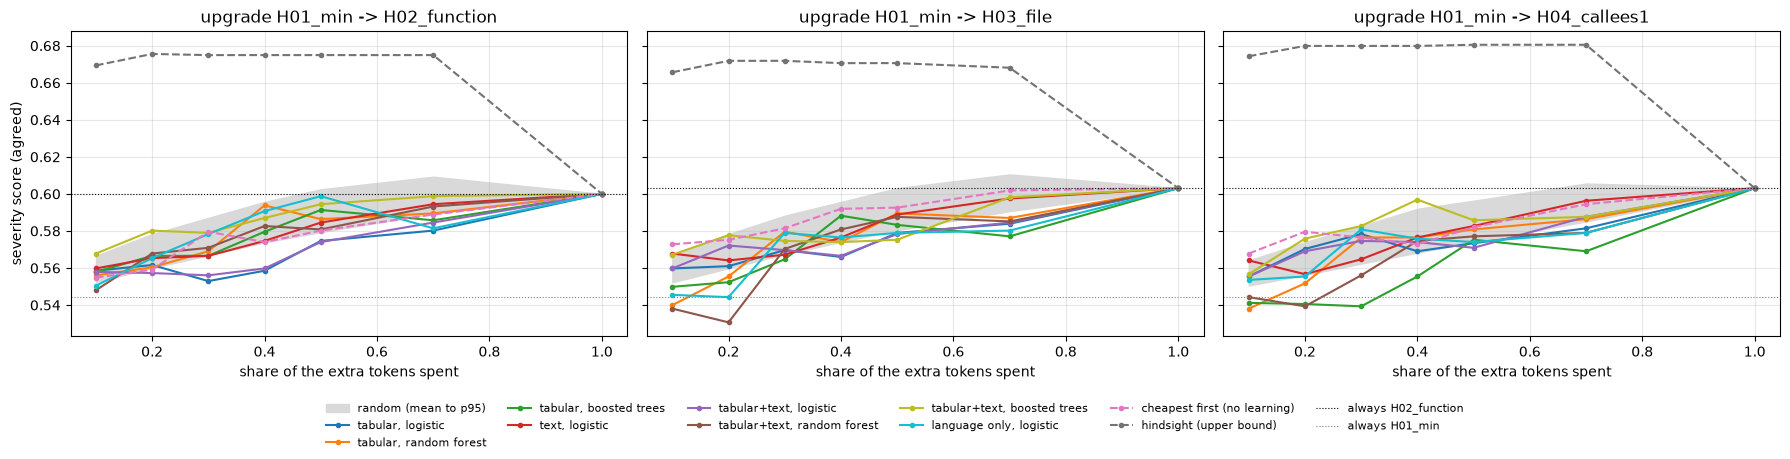

In [14]:
sc = f"score_{TARGET_WEIGHTING}"
show = [m for m in SCORES if m in PLOT_METHODS] or list(SCORES)[:6]
fig, axes = plt.subplots(1, len(UPGRADE_LEVELS), figsize=(6 * len(UPGRADE_LEVELS), 4.6), sharey=True)
for ax, up in zip(np.atleast_1d(axes), UPGRADE_LEVELS):
    t = BUDGET_TABLE[BUDGET_TABLE.upgrade_to == up]
    rr = t[t.method == show[0]]
    ax.fill_between(rr["spend"], [RAND[(up, f)]["score_mean"] for f in rr["spend"]],
                    [RAND[(up, f)]["score_p95"] for f in rr["spend"]], color="0.85", label="random (mean to p95)")
    palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#bcbd22",
               "#17becf", "#393b79", "#637939", "#ad494a", "#7b4173", "#3182bd", "#e6550d"]
    for k, m in enumerate(show):
        q = t[t.method == m]
        ax.plot(q["spend"], q[sc], "-", marker="o", ms=3, color=palette[k % len(palette)], label=m)
    for m, col in [("cheapest first (no learning)", "#e377c2"), ("hindsight (upper bound)", "0.45")]:
        q = t[t.method == m]
        ax.plot(q["spend"], q[sc], "--", marker="o", ms=3, color=col, label=m)
    ax.axhline(FIXED.loc[LIDX[up], sc], color="k", lw=0.8, ls=":", label=f"always {up}")
    ax.axhline(FIXED.loc[b_i, sc], color="0.5", lw=0.8, ls=":", label=f"always {BASE_LEVEL}")
    ax.set_title(f"upgrade {BASE_LEVEL} -> {up}")
    ax.set_xlabel("share of the extra tokens spent"); ax.grid(alpha=0.3)
np.atleast_1d(axes)[0].set_ylabel(f"severity score ({TARGET_WEIGHTING})")
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=8, loc="lower center", ncol=min(6, len(labels)), frameon=False)
plt.tight_layout(rect=(0, 0.06 + 0.035 * ((len(labels) - 1) // 6), 1, 1))
fig.savefig(OUT_DIR / FIG_NAME, dpi=150)
plt.show()

## 13. Save

`nonllm_oof_scores.csv` holds every hunk's out-of-fold score and fold; copy it next to the LLM notebook's results to put these models in its comparison.

In [15]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

AUC.to_csv(OUT_DIR / "nonllm_auc.csv", index=False)
BUDGET_TABLE.to_csv(OUT_DIR / "nonllm_budget_table.csv", index=False)
COMPARE.to_csv(OUT_DIR / "nonllm_bootstrap.csv", index=False)
GROUPS.to_csv(OUT_DIR / "nonllm_groups.csv")
SHUFFLE.to_csv(OUT_DIR / "nonllm_shuffled_labels.csv", index=False)
FIXED.to_csv(OUT_DIR / "fixed_levels.csv", index=False)
pd.DataFrame([{"upgrade_to": u, "spend": f, **v} for (u, f), v in RAND.items()]).to_csv(
    OUT_DIR / "random_upgrade.csv", index=False)
oof_df = pd.DataFrame({"hunk": hunks["hunk"], "pr": hunks["pr"], "repo": REPOS, "fold": FOLD_ID,
                       "y_wider": Y_COUNT, "y_wider_weighted": Y_WEIGHTED})
for name, s in SCORES.items():
    oof_df[f"score|{name}"] = s
oof_df.to_csv(OUT_DIR / "nonllm_oof_scores.csv", index=False)   # the LLM notebook can read this
pd.DataFrame({"repo": sorted(FOLD_OF), "fold": [FOLD_OF[r] for r in sorted(FOLD_OF)]}).to_csv(
    OUT_DIR / "folds.csv", index=False)
manifest = {
    "written_at": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "inputs": {k: str(v) for k, v in FILES.items()},
    "sha256": {k: sha256(v) for k, v in FILES.items()},
    "hunks": H, "references": R, "label": LABEL, "positives": int(Y.sum()),
    "cv": CV, "folds": len(FOLDS), "fold_hash": FOLD_HASH, "base_level": BASE_LEVEL,
    "upgrade_levels": UPGRADE_LEVELS, "main_upgrade": MAIN_UP, "spend": SPEND, "target_spend": TARGET_SPEND,
    "target_weighting": TARGET_WEIGHTING, "seeds": SEEDS, "n_random": N_RANDOM, "n_boot": N_BOOT,
    "tabular_features": int(XT.shape[1]),
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": sklearn.__version__},
    "note": "AACR-Bench 50% (93 PRs, 928 hunks, four levels). One reviewer run. No locked test set.",
}
(OUT_DIR / "nonllm_manifest.json").write_text(json.dumps(manifest, indent=1))
print("Saved to", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print("  ", p.name)

Saved to /Users/penglihua/Desktop/GitHub/CS536_Project/results/selector50_nonllm
   fixed_levels.csv
   folds.csv
   frontier_nonllm.png
   nonllm_auc.csv
   nonllm_bootstrap.csv
   nonllm_budget_table.csv
   nonllm_groups.csv
   nonllm_manifest.json
   nonllm_oof_scores.csv
   nonllm_shuffled_labels.csv
   random_upgrade.csv
